In [273]:
import os
import os.path as op
import numpy as np
import matplotlib.pyplot as plt

import hnn_core

from hnn_core import MPIBackend, JoblibBackend

import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/')
from optim_utils import set_params
from hnn_core.dipole import _rmse
from hnn_core.params import _short_name

from hnn_core import duecker_2025_ET_model, simulate_dipole, jones_2009_model
import matplotlib.pyplot as plt
from hnn_core.viz import plot_dipole, plot_psd, plot_tfr_morlet
import numpy as np

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'

which_model = 'calcium'
which_setting = 'new_neymotin'

### Feedforward

In [274]:
# Feedforward model parameters

scale_factor = 30000

if which_model == 'jones':
    net = jones_2009_model()
elif which_model == 'calcium':
    net = duecker_2025_ET_model()
tstop = 2000

location = 'proximal'
burst_std = 20               # Jones 2009: input bursts variance = 400

if which_setting == 'jones':
    weights_ampa_p = {'L2_basket': 1.2e-7, 'L2_pyramidal': 0.6e-7, 'L5_pyramidal': 0.6e-7, 'L5_basket': 1.2e-7}     # max values taken from Jones 2009 for high mu; 

    syn_delays_p = {'L2_basket': 4., 'L2_pyramidal': 5, 'L5_pyramidal': 5., 'L5_basket': 4}#{'L2_basket': 0.1, 'L5_pyramidal': 1., 'L5_basket': 1}                    # following https://modeldb.science/136803?tab=2&file=JonesEtAl2009/wiring_proc_2Dv2.hoc {'L2_basket': 4., 'L5_pyramidal': 5., 'L5_basket': 4} but this leads to no response at all
    
elif which_setting == 'neymotin':
    weights_ampa_p = {'L2_basket': 0.0, 'L2_pyramidal': 5.e-5, 'L5_pyramidal': 5.e-5, 'L5_basket': 0.0}     # max values taken from Jones 2009 for high mu; 

    
    syn_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1., 'L5_basket': 1.}#{'L2_basket': 0.1, 'L5_pyramidal': 1., 'L5_basket': 1} 
elif which_setting == 'hnn_core':
    weights_ampa_p = {'L2_pyramidal': 5.4e-5, 'L5_pyramidal': 5.4e-5}
    syn_delays_p = {'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}
elif which_setting == 'new_neymotin':
    weights_ampa_p = {'L2_basket': 0.0, 'L2_pyramidal': 5.e-5, 'L5_pyramidal': 5.e-5, 'L5_basket': 0.0}     # max values taken from Jones 2009 for high mu; 

    syn_delays_p = {'L2_basket': .1, 'L2_pyramidal': .1, 'L5_pyramidal': 1., 'L5_basket': 1.}

prox_seed_indv = 160 #int(np.random.uniform(500))
net.add_bursty_drive(
    'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=prox_seed_indv)

# with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
#     dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor=which_model)[0]

# dpl.scale(scale_factor)
# trial_idx = 0  # single trial simulated, choose the first index
# to emulate a larger patch of cortex, we can apply a simple scaling factor
# dpl.scale(scale_factor)


### Feedback

In [275]:
location = 'distal'
burst_std = 20              # I believe the std was the same for FB and FF inputs in Jones 2009

if which_setting == 'jones':
    weights_ampa_d = {'L2_basket': 1.2e-7*4, 'L5_pyramidal': 0.6e-7*4, 'L2_pyramidal': 0.6e-7*4}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc
    syn_delays_d = {'L2_basket': 4, 'L5_pyramidal': 5., 'L2_pyramidal': 5.}
    delay = 3
elif which_setting == 'neymotin':
    weights_ampa_d = {'L2_basket': 0, 'L5_pyramidal': 5.e-5, 'L2_pyramidal': 5.e-5}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc
    syn_delays_d = {'L2_basket': 5, 'L5_pyramidal': 5., 'L2_pyramidal': 5.}
    delay = 0
elif which_setting == 'hnn_core':
    delay = 0
    burst_std = 15
    weights_ampa_d = {'L2_pyramidal': 5.4e-5, 'L5_pyramidal': 5.4e-5}
    syn_delays_d = {'L2_pyramidal': 5., 'L5_pyramidal': 5.}
elif which_setting == 'new_neymotin':
    weights_ampa_d = {'L2_basket': 0, 'L5_pyramidal': 5.e-5*4, 'L2_pyramidal': 5.e-5*4}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc
    syn_delays_d = {'L2_basket': .1, 'L5_pyramidal': 1., 'L2_pyramidal': .1}
    delay = 3

dist_seed_indv = 370 #int(np.random.uniform(500))

net.add_bursty_drive(
    'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=dist_seed_indv)




In [276]:
prox_seed_indv, dist_seed_indv

(160, 370)

In [277]:
with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, bsl_cor=which_model)[0]
dpl.scale(scale_factor)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

In [278]:
import scipy.signal as signal
from scipy.signal import periodogram
fs = dpl.sfreq
ts_vec = dpl.times
N = len(ts_vec)



#f, P = periodogram(dpl.data['agg'], dpl.sfreq, window='hamming', nfft=len(dpl.data['agg']))
# Jones et al: overlapping 500 ms windows
f, P = signal.welch(dpl.data['agg'], fs=fs, window='hamming', nperseg=N/4, noverlap=N/8, nfft=N/4, return_onesided=True, scaling='spectrum')

# normalize the power spectrum
#P *= (f/f[-1])

In [279]:
from hnn_core.externals.mne import tfr_array_morlet

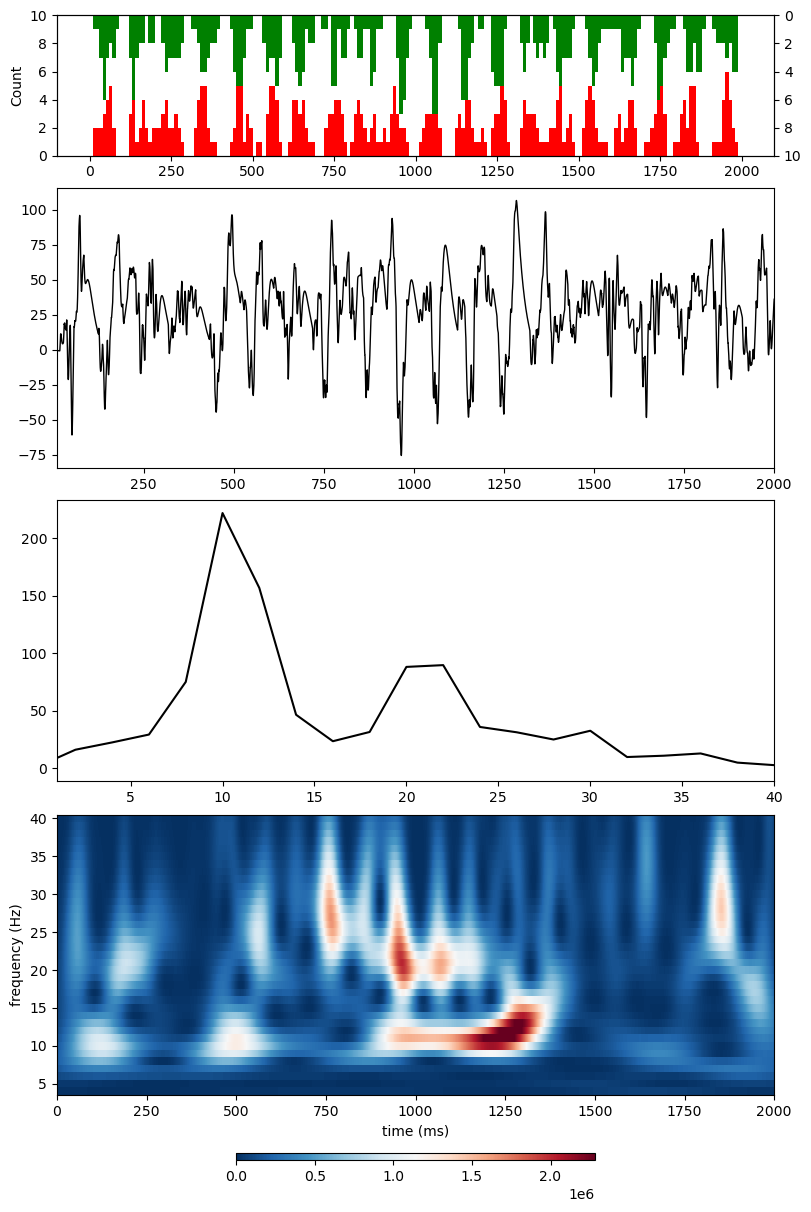

In [280]:
import numpy as np

fig, axes = plt.subplots(4, 1, constrained_layout=True, figsize=(8, 12), height_ratios=[0.5, 1, 1, 1])
tmin, tmax = 10, tstop  # exclude the initial burn-in period from the plots

bins = np.arange(0, tstop+10, 10)  # histogram bins
# We'll make a copy of the dipole before smoothing in order to compare
# window_len = 10  # convolve with a 10 ms-long Hamming window
# dpl_smooth = dpl.copy().smooth(window_len)

# proximal and distal histogram
spike_prox = np.array(net.cell_response.spike_times_by_type['alpha_prox']).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['alpha_dist']).reshape(-1,1)

axes[0].hist(spike_prox, bins, color='r')
axes[0].set_ylim([0, 10])
axes[0].set_ylabel('Count')
ax1tw = axes[0].twinx()
ax1tw.hist(spike_dist, bins, color='g')
ax1tw.set_ylim([0, 10])
ax1tw.invert_yaxis()

axes[1].plot(dpl.times, dpl.data['agg'], color='k', linewidth=1)
axes[1].set_xlim((tmin, tmax))

axes[2].plot(f, P, color='k')
axes[2].set_xlim((1, 40))
#axes[2].set_xscale('log')

freqs = np.arange(4, 41, 1)

power = tfr_array_morlet(dpl.data['agg'][None, None, :], sfreq=fs, freqs=freqs,
                                 n_cycles=5, output='power')

power = power[0, 0, ...] * (freqs/freqs[-1]).reshape(-1,1)  # normalize the power spectrum
im = axes[3].pcolormesh(dpl.times, freqs, power, cmap='RdBu_r',
                       shading='auto', vmin=0, vmax=np.max(power)*0.9, rasterized=True)
axes[3].set_xlabel('time (ms)')
axes[3].set_ylabel('frequency (Hz)')


plt.colorbar(im, ax=axes[3], orientation='horizontal', pad=0.05, aspect=50, shrink=0.5)
fig.savefig(os.path.join(pathfig, f'alpha_beta_complex_{which_model}_{which_setting}_no_delay.png'), dpi=300)


In [281]:
# try different settings
prox_seed = np.random.uniform(1000, 0, (10,))
dist_seed = np.random.uniform(1000, 0, (10,))

dpls = []
for sp, sd in zip(prox_seed, dist_seed):

    if which_model == 'jones':
        net = jones_2009_model()
    elif which_model == 'calcium':
        net = duecker_2025_ET_model()
        
    net.add_bursty_drive(
        'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='proximal',
        weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=int(sp))
    net.add_bursty_drive(
        'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='distal',
        weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=int(sd))

    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=2000, bsl_cor=which_model)[0]
        dpl.scale(scale_factor)
        dpls.append(dpl)


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

In [282]:
fs = dpl.sfreq
ts_vec = dpl.times
N = len(ts_vec)

P_all = np.zeros((len(dpls), int(N/4 + 1)))
for i, dpl in enumerate(dpls):

    f, P = signal.welch(dpl.data['agg'], fs=fs, window='hamming', nperseg=N/2, noverlap=N/4, nfft=N/2, return_onesided=True, scaling='spectrum')

    # normalize the power spectrum
    #P *= (f/f[-1])

    P_all[i, :] = P

P_avg = np.mean(P_all, axis=0)
P_ste = np.std(P_all, axis=0) / np.sqrt(len(dpls))

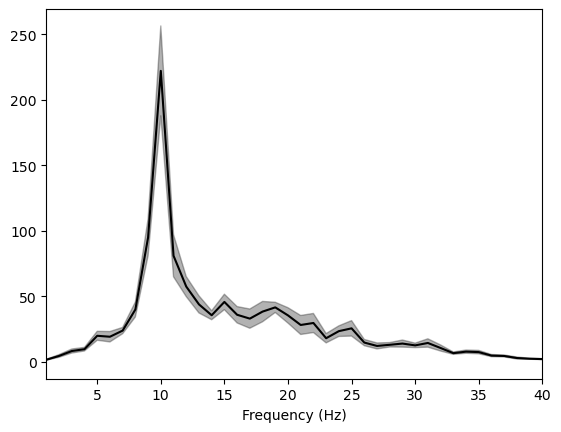

In [283]:
fig, ax = plt.subplots()

ax.plot(f, P_avg, color='k')
ax.fill_between(f, P_avg - P_ste, P_avg + P_ste,
                color='k', alpha=0.3, label='mean ± ste')
ax.set_xlabel('Frequency (Hz)')
ax.set_xlim((1, 40))

fig.savefig(os.path.join(pathfig, f'alpha_beta_complex_{which_model}_{which_setting}_adjust_delay_10trials.png'), dpi=300)
fig.savefig(os.path.join(pathfig, f'alpha_beta_complex_{which_model}_{which_setting}_adjust_delay_10trials.pdf'), dpi=300)

## Symmetry index

In [284]:
dt = np.diff(dpl.times)[0]
fs = 1000/dt

In [285]:
# symmetry index

from scipy.signal import butter, lfilter, find_peaks

def butter_bandpass(lowcut, highcut, fs, order=5):
        nyq = 0.5 * fs
        low = lowcut / nyq
        high = highcut / nyq
        b, a = butter(order, [low, high], btype='band')
        return b, a


def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = lfilter(b, a, data)
    return y

def symmetry_index(dpl, lowcut=7, highcut=29, show_plot=False):

    cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
        
    filt_dpl = butter_bandpass_filter(dpl.data['agg'], lowcut, highcut, fs, order=2)
    peaks, _ = find_peaks(filt_dpl, prominence=0.01)
    troughs, _ = find_peaks(-filt_dpl, prominence=0.01)

    if len(peaks) == len(troughs):
        if troughs[0] < peaks[0]:
            sind = (np.abs(filt_dpl[peaks[:-1]]) - np.abs(filt_dpl[troughs[1:]]))/(np.abs(filt_dpl[peaks[:-1]]) + np.abs(filt_dpl[troughs[1:]]))
        else:
            sind = (np.abs(filt_dpl[peaks]) - np.abs(filt_dpl[troughs]))/(np.abs(filt_dpl[peaks]) + np.abs(filt_dpl[troughs]))
    elif len(peaks) > len(troughs):
         sind = (np.abs(filt_dpl[peaks[int(len(peaks)-len(troughs)):]]) - np.abs(filt_dpl[troughs]))/(np.abs(filt_dpl[peaks[int(len(peaks)-len(troughs)):]]) + np.abs(filt_dpl[troughs]))
    elif len(peaks) < len(troughs):

        peak_diff = int(len(troughs)-len(peaks))
        if troughs[0] < peaks[0]:
            sind = (np.abs(filt_dpl[peaks]) - np.abs(filt_dpl[troughs[peak_diff:]]))/(np.abs(filt_dpl[peaks]) + np.abs(filt_dpl[troughs[peak_diff:]]))
        else:
            sind = (np.abs(filt_dpl[peaks]) - np.abs(filt_dpl[troughs[:-peak_diff]]))/(np.abs(filt_dpl[peaks]) + np.abs(filt_dpl[troughs[:-peak_diff]]))
         

    if show_plot:

        fig, ax = plt.subplots(1, 1, figsize=(7, 5))
        ax.plot(dpl.times, dpl.data['agg'], label='raw', color=cols[0])
        ax.plot(dpl.times, filt_dpl, label='filtered', color=cols[1])
        ax.plot(dpl.times[peaks], filt_dpl[peaks], 'x', label='peaks', color=cols[2])
        ax.plot(dpl.times[troughs], filt_dpl[troughs], 'x', label='troughs', color=cols[3])
        ax.set_xlabel('time (ms)')
        ax.set_ylabel('dipole (nAm)')
        ax.legend()

        fig.savefig(os.path.join(pathfig, f'symmetry_index_{which_model}_{which_setting}.png'), dpi=300)
        fig.savefig(os.path.join(pathfig, f'symmetry_index_{which_model}_{which_setting}.pdf'), dpi=300)

    return sind


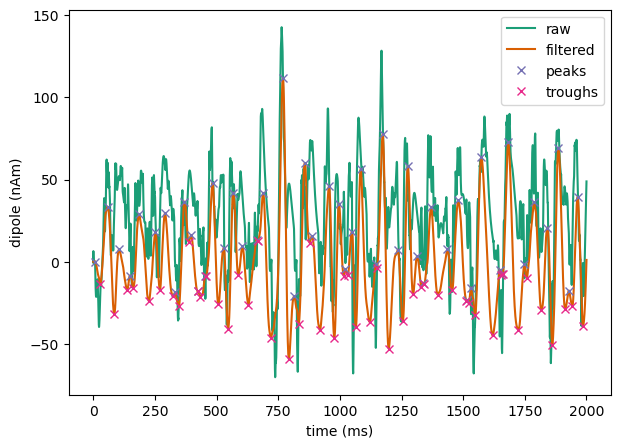

In [286]:
sind = symmetry_index(dpl, lowcut=7, highcut=29, show_plot=True)


In [287]:
sind = np.array(())

for i,trl in enumerate(dpls):
    trl.scale(scale_factor)
    sind = np.append(sind, symmetry_index(trl, lowcut=7, highcut=29, show_plot=False))

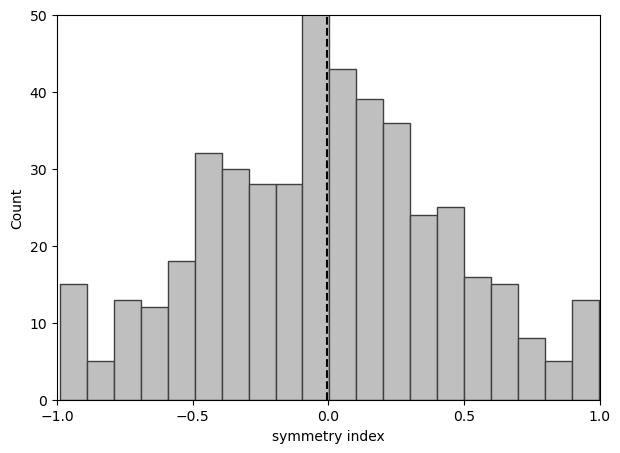

In [288]:
fig, ax = plt.subplots(1, 1, figsize=(7, 5))
ax.hist(sind, bins=20, color=[0.75, 0.75, 0.75], edgecolor=[0.25, 0.25, 0.25])
ax.set_xlabel('symmetry index')
ax.set_ylabel('Count')
ax.plot(np.ones(50,)*np.median(sind), np.linspace(0,50), 'k', label='mean', linestyle='--')  
ax.set_xticks(np.arange(-1, 1.1, 0.5))
ax.set_yticks(np.arange(0, 51, 10))
ax.set_ylim((0, 50))
ax.set_xlim((-1, 1))
fig.savefig(os.path.join(pathfig, f'symmetry_index_10_trials_{which_model}_{which_setting}.png'), dpi=300)
fig.savefig(os.path.join(pathfig, f'symmetry_index_10_trials_{which_model}_{which_setting}.pdf'), dpi=300)

In [289]:
# Delay between proximal and distal input -> alpha/beta ratio?
from scipy.signal import periodogram
import pickle
delays = np.arange(0, 96, 5)
alpha_beta_ratio = np.zeros(len(delays))
for i, delay in enumerate(delays):

    if which_model == 'jones':
        net = jones_2009_model()
    elif which_model == 'calcium':
        net = duecker_2025_ET_model()
    tstop = 1000

    burst_std = 20               # Jones 2009: input bursts variance = 400

    net.add_bursty_drive(
        'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='proximal',
        weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=prox_seed_indv)

    net.add_bursty_drive(
        'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='distal',
        weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=dist_seed_indv)

    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=tstop, bsl_cor=which_model, change_seed_per_drive=False)[0]

    N = len(dpl.data['agg'])
    freqs, Pxx = signal.welch(dpl.data['agg'], fs=fs, window='hamming', nperseg=N/2, noverlap=N/4, nfft=N/2, return_onesided=True, scaling='spectrum')

    alpha_pow = np.mean(Pxx[(freqs >= 8) & (freqs <= 12)])
    beta_pow = np.mean(Pxx[(freqs >= 15) & (freqs <= 30)])
    alpha_beta_ratio[i] = beta_pow/alpha_pow

delay_ratio = dict()
delay_ratio['delay'] = delays
delay_ratio['alpha_beta_ratio'] = alpha_beta_ratio

with open(f'delay_ratio_{which_model}_{which_setting}.pkl', 'wb') as f:
    pickle.dump(delay_ratio, f)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/parallel_backends.py:211: UserWarning: Received KeyboardInterrupt. Stopping simulation process...
  warn("Received KeyboardInterrupt. Stopping simulation process...")


RuntimeError: MPI simulation failed. Return code: 1

In [ ]:
# Variance of drive on alpha beta ratio
from scipy.signal import periodogram
burst_std = np.arange(np.sqrt(200), np.sqrt(600), 2)
alpha_beta_ratio_prox_std = np.zeros(len(burst_std))
for i, bstd in enumerate(burst_std):

    if which_model == 'jones':
        net = jones_2009_model()
    elif which_model == 'calcium':
        net = duecker_2025_ET_model()
    tstop = 1000

    net.add_bursty_drive(
        'alpha_prox', tstart=50., burst_rate=10, burst_std=bstd, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='proximal',
        weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=prox_seed_indv)

    net.add_bursty_drive(
        'alpha_dist', tstart=50.+5, burst_rate=10, burst_std=20, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='distal',
        weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=dist_seed_indv)

    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor=which_model, change_seed_per_drive=False)[0]

    N = len(dpl.data['agg'])
    freqs, Pxx = signal.welch(dpl.data['agg'], fs=fs, window='hamming', nperseg=N/2, noverlap=N/4, nfft=N/2, return_onesided=True, scaling='spectrum')

    alpha_pow = np.mean(Pxx[(freqs >= 8) & (freqs <= 12)])
    beta_pow = np.mean(Pxx[(freqs >= 15) & (freqs <= 30)])
    alpha_beta_ratio_prox_std[i] = beta_pow/alpha_pow

# vary alpha variance
alpha_beta_ratio_dist_std = np.zeros(len(burst_std))
for i, bstd in enumerate(burst_std):
    if which_model == 'jones':
        net = jones_2009_model()
    elif which_model == 'calcium':
        net = duecker_2025_ET_model()
    tstop = 1000

    net.add_bursty_drive(
        'alpha_prox', tstart=50., burst_rate=10, burst_std=20, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='proximal',
        weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=prox_seed_indv)

    net.add_bursty_drive(
        'alpha_dist', tstart=50.+5, burst_rate=10, burst_std=bstd, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='distal',
        weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=dist_seed_indv)

    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor=which_model, change_seed_per_drive=False)[0]

    N = len(dpl.data['agg'])
    freqs, Pxx = signal.welch(dpl.data['agg'], fs=fs, window='hamming', nperseg=N/2, noverlap=N/4, nfft=N/2, return_onesided=True, scaling='spectrum')


    alpha_pow = np.mean(Pxx[(freqs >= 8) & (freqs <= 12)])
    beta_pow = np.mean(Pxx[(freqs >= 15) & (freqs <= 30)])
    alpha_beta_ratio_dist_std[i] = beta_pow/alpha_pow

burst_std_ratio = dict()
burst_std_ratio['burst_std'] = burst_std
burst_std_ratio['alpha_beta_ratio_prox'] = alpha_beta_ratio_prox_std
burst_std_ratio['alpha_beta_ratio_dist'] = alpha_beta_ratio_dist_std


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

In [ ]:
import pickle
with open(f'burst_std_ratio_{which_model}_{which_setting}.pkl', 'wb') as f:
    pickle.dump(burst_std_ratio, f)

In [ ]:
# vary amplitude (number of cells)

num_cells = np.arange(5, 15, 1)
alpha_beta_ratio_num_cells_dist = np.zeros(len(num_cells))
for i, n_cells in enumerate(num_cells):
    if which_model == 'jones':
        net = jones_2009_model()
    elif which_model == 'calcium':
        net = duecker_2025_ET_model()
    tstop = 1000

    burst_std = 20               # Jones 2009: input bursts variance = 400

    net.add_bursty_drive(
        'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='proximal',
        weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=prox_seed_indv)

    net.add_bursty_drive(
        'alpha_dist', tstart=50.+5, burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=int(n_cells), location='distal',
        weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=dist_seed_indv)

    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor=which_model, change_seed_per_drive=False)[0]

    N = len(dpl.data['agg'])
    freqs, Pxx = signal.welch(dpl.data['agg'], fs=fs, window='hamming', nperseg=N/2, noverlap=N/4, nfft=N/2, return_onesided=True, scaling='spectrum')


    alpha_pow = np.mean(Pxx[(freqs >= 8) & (freqs <= 12)])
    beta_pow = np.mean(Pxx[(freqs >= 15) & (freqs <= 30)])
    alpha_beta_ratio_num_cells_dist[i] = beta_pow/alpha_pow

alpha_beta_ratio_num_cells_prox = np.zeros(len(num_cells))
for i, n_cells in enumerate(num_cells):
    if which_model == 'jones':
        net = jones_2009_model()
    elif which_model == 'calcium':
        net = duecker_2025_ET_model()
    tstop = 1000

    burst_std = 20               # Jones 2009: input bursts variance = 400

    net.add_bursty_drive(
        'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=int(n_cells), location='proximal',
        weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=prox_seed_indv)

    net.add_bursty_drive(
        'alpha_dist', tstart=50.+5, burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=10, location='distal',
        weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=dist_seed_indv)

    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor=which_model, change_seed_per_drive=False)[0]

    N = len(dpl.data['agg'])
    freqs, Pxx = signal.welch(dpl.data['agg'], fs=fs, window='hamming', nperseg=N/2, noverlap=N/4, nfft=N/2, return_onesided=True, scaling='spectrum')

    alpha_pow = np.mean(Pxx[(freqs >= 8) & (freqs <= 12)])
    beta_pow = np.mean(Pxx[(freqs >= 15) & (freqs <= 30)])
    alpha_beta_ratio_num_cells_prox[i] = beta_pow/alpha_pow

num_cells_ratio = dict()
num_cells_ratio['num_cells'] = num_cells
num_cells_ratio['alpha_beta_ratio_prox'] = alpha_beta_ratio_num_cells_prox
num_cells_ratio['alpha_beta_ratio_dist'] = alpha_beta_ratio_num_cells_dist
with open(f'num_cells_ratio_{which_model}_{which_setting}.pkl', 'wb') as f:
    pickle.dump(num_cells_ratio, f)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

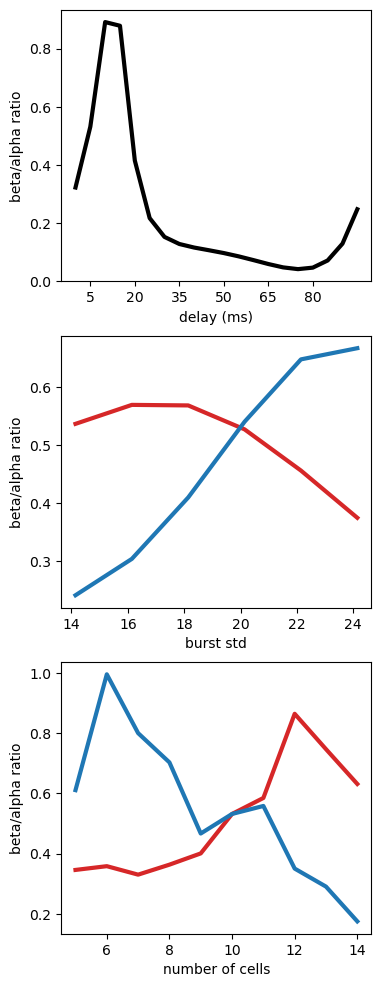

In [ ]:
with open(f'delay_ratio_{which_model}_{which_setting}.pkl', 'rb') as f:
    delay_ratio = pickle.load(f)

fig, ax = plt.subplots(3, 1, figsize=(4, 12))
ax[0].plot(delay_ratio['delay'], delay_ratio['alpha_beta_ratio'], 'k', linewidth=3)
ax[0].set_xlabel('delay (ms)')
ax[0].set_ylabel('beta/alpha ratio')
ax[0].set_xticks(np.arange(5, 91, 15))


with open(f'burst_std_ratio_{which_model}_{which_setting}.pkl', 'rb') as f:
   burst_std_ratio = pickle.load(f)
   
ax[1].plot(burst_std_ratio['burst_std'], burst_std_ratio['alpha_beta_ratio_prox'], 'tab:red', label='vary FF', linewidth=3)
ax[1].plot(burst_std_ratio['burst_std'], burst_std_ratio['alpha_beta_ratio_dist'], 'tab:blue', label='vary FB', linewidth=3)


with open(f'num_cells_ratio_{which_model}_{which_setting}.pkl', 'rb') as f:
    num_cells_ratio = pickle.load(f)

ax[2].plot(num_cells_ratio['num_cells'], num_cells_ratio['alpha_beta_ratio_prox'], 'tab:red', label='vary FF', linewidth=3)
ax[2].plot(num_cells_ratio['num_cells'], num_cells_ratio['alpha_beta_ratio_dist'], 'tab:blue', label='vary FB', linewidth=3)
ax[2].set_xlabel('number of cells')
ax[1].set_xlabel('burst std')
ax[1].legend()

for a in ax:
    a.set_ylabel('beta/alpha ratio')

fig.savefig(os.path.join(pathfig, f'alpha_beta_ratio_{which_model}_{which_setting}.png'), dpi=300)
fig.savefig(os.path.join(pathfig, f'alpha_beta_ratio_{which_model}_{which_setting}.pdf'), dpi=300)

(1.0, 40.0)

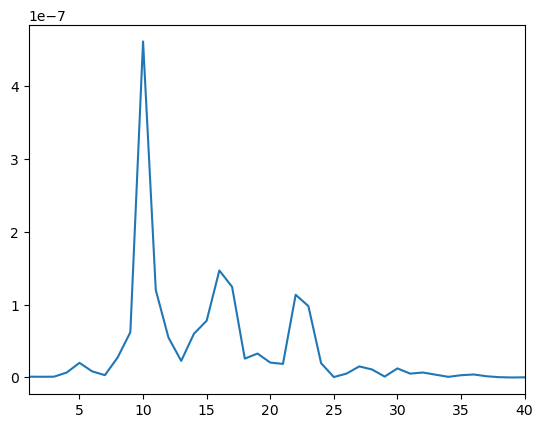

In [ ]:
plt.plot(f, Pxx)
plt.xlim((1, 40))

In [ ]:
# Feedforward model parameters

scale_factor = 30000

if which_model == 'jones':
    net = jones_2009_model()
elif which_model == 'calcium':
    net = duecker_2025_ET_model()
tstop = 2000

location = 'proximal'
burst_std = 20               # Jones 2009: input bursts variance = 400


weights_ampa_p = {'L2_basket': 0.0, 'L2_pyramidal': 5.e-5, 'L5_pyramidal': 5.e-5, 'L5_basket': 0.0}     # max values taken from Jones 2009 for high mu; 

syn_delays_p = {'L2_basket': .1, 'L2_pyramidal': .1, 'L5_pyramidal': 1., 'L5_basket': 1.}

net.add_bursty_drive(
    'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=prox_seed_indv)

location = 'distal'
burst_std = 20              # I believe the std was the same for FB and FF inputs in Jones 2009

weights_ampa_d = {'L2_basket': 0, 'L5_pyramidal': 5.e-5*4, 'L2_pyramidal': 5.e-5*4}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc
syn_delays_d = {'L2_basket': .1, 'L5_pyramidal': 1., 'L2_pyramidal': .1}
delay = 3


net.add_bursty_drive(
    'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=dist_seed_indv)


with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, bsl_cor=which_model)[0]
dpl.scale(scale_factor)

In [ ]:
import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/SpectralEvents')
import spectralevents

In [ ]:
tfr = power.reshape((1, len(freqs), -1))
events = spectralevents.find_events(tfr, dpl.times, freqs, event_band=[15, 30], threshold_FOM=5)

array([1, 0, 2])

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_93285/2878579339.py:1: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  onset = int(np.where(dpl.times == events[0][1]['Event Onset Time'])[0])
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_93285/2878579339.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  offset = int(np.where(dpl.times == events[0][1]['Event Offset Time'])[0])


Text(0, 0.5, 'dipole (nAm)')

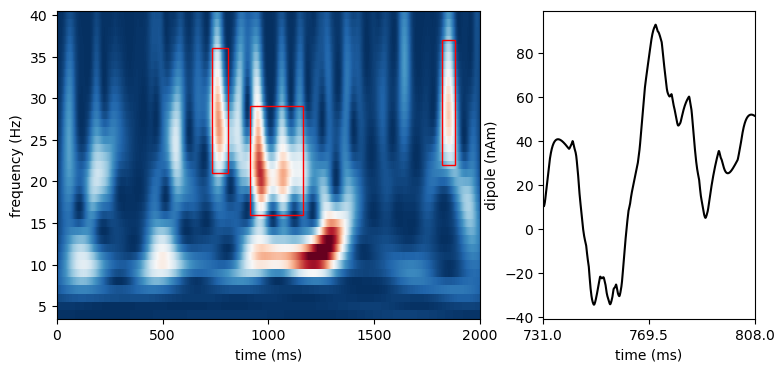

In [ ]:

onset = int(np.where(dpl.times == events[0][1]['Event Onset Time'])[0])
offset = int(np.where(dpl.times == events[0][1]['Event Offset Time'])[0])

beta_event_delay3 = dpl.data['agg'][onset:offset]
beta_event_times = dpl.times[onset:offset]

onset_time = []
for e in events[0]:
    onset_time.append(e['Event Onset Time'])

onset_time = np.array(onset_time)
np.argsort(onset_time)    

fig, ax = plt.subplots(1,4, figsize=(9, 4), width_ratios=[1., 0.25, 0.25, 0.25])
im = ax[0].pcolormesh(dpl.times, freqs, power, cmap='RdBu_r',
                       shading='auto', vmin=0, vmax=np.max(power)*0.9, rasterized=True)

for e in events[0]:
    ax[0].add_patch(plt.Rectangle((e['Event Onset Time'], e['Lower Frequency Bound']),e['Event Duration'], e['Upper Frequency Bound'] - e['Lower Frequency Bound'], ec='r', fc='none'))
ax[0].set_xlabel('time (ms)')
ax[0].set_ylabel('frequency (Hz)')
ax[0].set_xticks(np.arange(0, 2001, 500))
ax[1].plot(beta_event_times,beta_event_delay3, 'k')
ax[1].set_xlim((beta_event_times[0], beta_event_times[-1]))
ax[1].set_xticks(np.linspace(np.round(beta_event_times[0]), np.round(beta_event_times[-1]), 3))
ax[1].set_xlabel('time (ms)')
ax[0].set_xlabel('time (ms)')

ax[1].set_ylabel('dipole (nAm)')

In [ ]:
# Feedforward model parameters
max_beta_delay = delay_ratio['delay'][np.argmax(delay_ratio['alpha_beta_ratio'])]
scale_factor = 30000

if which_model == 'jones':
    net = jones_2009_model()
elif which_model == 'calcium':
    net = duecker_2025_ET_model()
tstop = 2000

# proximal drive
location = 'proximal'
burst_std = 20               # Jones 2009: input bursts variance = 400

weights_ampa_p = {'L2_basket': 0.0, 'L2_pyramidal': 5.e-5, 'L5_pyramidal': 5.e-5, 'L5_basket': 0.0}     # max values taken from Jones 2009 for high mu; 

syn_delays_p = {'L2_basket': .1, 'L2_pyramidal': .1, 'L5_pyramidal': 1., 'L5_basket': 1.}

prox_seed_indv = 160 #int(np.random.uniform(500))
net.add_bursty_drive(
    'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=prox_seed_indv)


# distal drive
location = 'distal'
burst_std = 20              # I believe the std was the same for FB and FF inputs in Jones 2009

weights_ampa_d = {'L2_basket': 0, 'L5_pyramidal': 5.e-5*4, 'L2_pyramidal': 5.e-5*4}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc
syn_delays_d = {'L2_basket': .1, 'L5_pyramidal': 1., 'L2_pyramidal': .1}
delay = max_beta_delay

dist_seed_indv = 370 #int(np.random.uniform(500))

net.add_bursty_drive(
    'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=dist_seed_indv)


with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, bsl_cor=which_model)[0]
dpl.scale(scale_factor)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

In [ ]:
from matplotlib.gridspec import GridSpec

freqs = np.arange(4, 41, 1)

power = tfr_array_morlet(dpl.data['agg'][None, None, :], sfreq=fs, freqs=freqs,
                                 n_cycles=5, output='power')

power = power[0, 0, ...] * (freqs/freqs[-1]).reshape(-1,1)  # normalize the power spectrum

tfr = power.reshape((1, len(freqs), -1))
events = spectralevents.find_events(tfr, dpl.times, freqs, event_band=[20, 30], threshold_FOM=4)

onset_time = []
offset_time = []
for e in events[0]:
    onset_time.append(e['Event Onset Time'])
    offset_time.append(e['Event Offset Time'])

onset_time = np.array(onset_time)
offset_time = np.array(offset_time)   
onset_time

array([ 930.85 ,  749.125, 1816.25 , 1342.525, 1624.15 ])

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_93285/1843455623.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  onset = int(np.where(dpl.times == events[0][o]['Event Onset Time'])[0]-50/dt)
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_93285/1843455623.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  offset = int(np.where(dpl.times == events[0][o]['Event Offset Time'])[0])
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_93285/1843455623.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your 

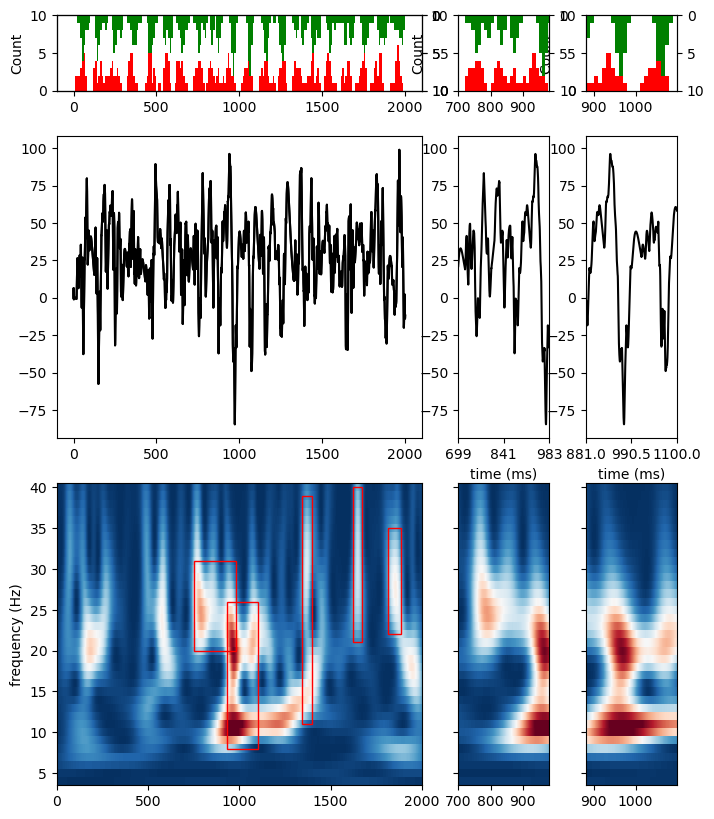

In [ ]:
fig, ax = plt.subplots(3,3, height_ratios=[0.25, 1,1], width_ratios=[1., 0.25, 0.25], figsize=(8, 10))   

onset_sort = np.argsort(onset_time)
for i,o in enumerate(onset_sort[:2]):

    onset = int(np.where(dpl.times == events[0][o]['Event Onset Time'])[0]-50/dt)
    offset = int(np.where(dpl.times == events[0][o]['Event Offset Time'])[0])

    beta_event_delay = dpl.data['agg'][onset:offset]
    beta_event_times = dpl.times[onset:offset]


    spike_prox = np.array(net.cell_response.spike_times_by_type['alpha_prox']).reshape(-1,1)
    spike_dist = np.array(net.cell_response.spike_times_by_type['alpha_dist']).reshape(-1,1)

    ax[0,0].hist(spike_prox, bins, color='r')
    ax[0,0].set_ylim([0, 10])
    ax[0,0].set_ylabel('Count')
    ax1tw = ax[0,0].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 10])
    ax1tw.invert_yaxis()

    ax[1,0].plot(dpl.times, dpl.data['agg'], color='k')
    ax[1,0].set_xticks(np.arange(0, 2001, 500))

    im = ax[2,0].pcolormesh(dpl.times, freqs, power, cmap='RdBu_r',
                        shading='auto', vmin=0, vmax=np.max(power)*0.9, rasterized=True)

    for e in events[0]:
        ax[2,0].add_patch(plt.Rectangle((e['Event Onset Time'], e['Lower Frequency Bound']),e['Event Duration'], e['Upper Frequency Bound'] - e['Lower Frequency Bound'], ec='r', fc='none'))
    ax[2,0].set_ylabel('frequency (Hz)')

    ax[0,0].set_xticks(np.arange(0, 2001, 500))
    ax[1,0].set_xticks(np.arange(0, 2001, 500))


    # zoom in on beta event

    ax[0,i+1].hist(spike_prox, bins, color='r')
    ax[0,i+1].set_ylim([0, 10])
    ax[0,i+1].set_ylabel('Count')
    ax[0,i+1].set_xlim((beta_event_times[0], beta_event_times[-1]))
    ax2tw = ax[0,i+1].twinx()
    ax2tw.hist(spike_dist, bins, color='g')
    ax2tw.set_ylim([0, 10])
    ax2tw.invert_yaxis()

    ax[1,i+1].plot(dpl.times, dpl.data['agg'], color='k')
    ax[1,i+1].set_xlim((beta_event_times[0], beta_event_times[-1]))
    ax[1,i+1].set_xticks(np.linspace(np.round(beta_event_times[0]), np.round(beta_event_times[-1]), 3))
    ax[1,i+1].set_xlabel('time (ms)')
    im = ax[2,i+1].pcolormesh(dpl.times, freqs, power, cmap='RdBu_r',
                        shading='auto', vmin=0, vmax=np.max(power)*0.9, rasterized=True)
    ax[2,i+1].set_xlim((beta_event_times[0], beta_event_times[-1]))
    ax[2,i+1].set_yticklabels([])





In [ ]:
dt

np.float64(0.025)